# Which topics is *this* class stuck on, and how early can you tell?

Teachers can watch AI-tutor conversations live, but not hundreds of them. This notebook asks whether a class-level "stuck topic" signal can be computed from the first few problems students do, using real classroom data.

**Data:** ASSISTments 2009-2010 skill builder (corrected, collapsed), a public dataset of middle-school math practice: about 4,200 students, 250 classes and 101 skills.

**Definitions**
- A student **masters** a skill when they get 3 problems in a row right (ASSISTments' own skill-builder rule).
- A class is **stuck** on a skill when at least half of its students (with 3+ problems on that skill) never master it. Only class-skill pairs with 5+ such students are used.
- Signals use only each student's **first k problems** on the skill, so they are available early.
- Cross-validation is grouped by class, so no class appears in both training and test folds.

In [1]:
import pandas as pd, numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, GroupKFold
import matplotlib.pyplot as plt
# Public ASSISTments 2009-2010 skill builder file (download from the ASSISTments datasets page into this folder)
PATH = 'skill_builder_data_corrected_collapsed.csv'
d = pd.read_csv(PATH, encoding='latin1', low_memory=False).dropna(subset=['skill_name']).sort_values('order_id')
d['correct'] = (d.correct == 1).astype(int)
key = ['student_class_id','skill_name','user_id']
print(f"{d.user_id.nunique():,} students, {d.student_class_id.nunique()} classes, {d.skill_name.nunique()} skills, {len(d):,} responses")

4,151 students, 245 classes, 101 skills, 274,590 responses


In [2]:
def mastered(x):
    run = 0
    for v in x.values:
        run = run + 1 if v == 1 else 0
        if run >= 3: return 1
    return 0
stu = d.groupby(key).correct.agg(n='size', mastered=mastered).reset_index()
stu = stu[stu.n >= 3]

def class_table(k):
    fk = d.groupby(key).head(k).groupby(key).agg(fc=('correct','mean'), hints=('hint_count','mean'), att=('attempt_count','mean')).reset_index()
    t = stu.merge(fk, on=key)
    c = t.groupby(['student_class_id','skill_name']).agg(students=('user_id','size'), nonmastery=('mastered', lambda x: 1-x.mean()),
            pct_correct=('fc','mean'), hints=('hints','mean'), retries=('att','mean')).reset_index()
    c = c[c.students >= 5].copy(); c['stuck'] = (c.nonmastery >= .5).astype(int)
    s = c.groupby('skill_name').agg(sn=('nonmastery','sum'), cnt=('nonmastery','size'))
    c = c.join(s, on='skill_name'); c = c[c.cnt >= 3].copy()
    c['topic_difficulty'] = (c.sn - c.nonmastery) / (c.cnt - 1)   # from OTHER classes only
    return c

c3 = class_table(3)
print(f"{len(c3)} class-skill pairs; {c3.stuck.mean():.0%} are stuck")

1171 class-skill pairs; 22% are stuck


## 1. Is "stuck" a property of the topic, or of the class?

In [3]:
v = c3.groupby('skill_name').stuck.agg(['mean','size']); v = v[v['size'] >= 5]
mixed = ((v['mean'] > 0) & (v['mean'] < 1)).mean()
print(f"Of {len(v)} skills taught in 5+ classes, {mixed:.0%} are stuck in some classes and fine in others.")

Of 70 skills taught in 5+ classes, 84% are stuck in some classes and fine in others.


Most topics are hard for *some* classes, not all. A fixed list of "hard topics" will miss class-specific trouble and flag classes that are fine.

## 2. Which signal finds stuck class-topics best?

In [4]:
gk = GroupKFold(5)
def score(c, cols):
    p = cross_val_predict(LogisticRegression(max_iter=1000), c[cols], c.stuck, cv=gk, groups=c.student_class_id, method='predict_proba')[:,1]
    k = int(.2*len(c)); top = np.argsort(-p)[:k]
    return roc_auc_score(c.stuck, p), c.stuck.values[top].mean()
rows = []
for name, cols in [('topic difficulty (other classes)', ['topic_difficulty']),
                   ("this class's % correct", ['pct_correct']),
                   ('+ hints and retries', ['pct_correct','hints','retries']),
                   ('topic difficulty + this class', ['topic_difficulty','pct_correct'])]:
    auc, prec = score(c3, cols); rows.append(dict(signal=name, AUC=round(auc,3), precision_top20=round(prec,3)))
print(f"base rate: {c3.stuck.mean():.0%} of class-topics are stuck")
pd.DataFrame(rows)

base rate: 22% of class-topics are stuck


,signal,AUC,precision_top20
0,topic difficulty (other classes),0.733,0.530
1,this class's % correct,0.840,0.611
2,+ hints and retries,0.836,0.603
3,topic difficulty + this class,0.875,0.632


- The class's own first 3 problems per student beat a hard-topics list (AUC 0.84 vs 0.73).
- Combining both is best (AUC ~0.88): of the top 20% flagged class-topics, about **63% are truly stuck, roughly 3x the 22% base rate**.
- Hints and retries add nothing at the class level once % correct is known. (They may still matter per student.)

## 3. How early? Signal strength vs. problems seen per student

first 1 problem(s) per student: AUC 0.822
first 2 problem(s) per student: AUC 0.860
first 3 problem(s) per student: AUC 0.875
first 5 problem(s) per student: AUC 0.891


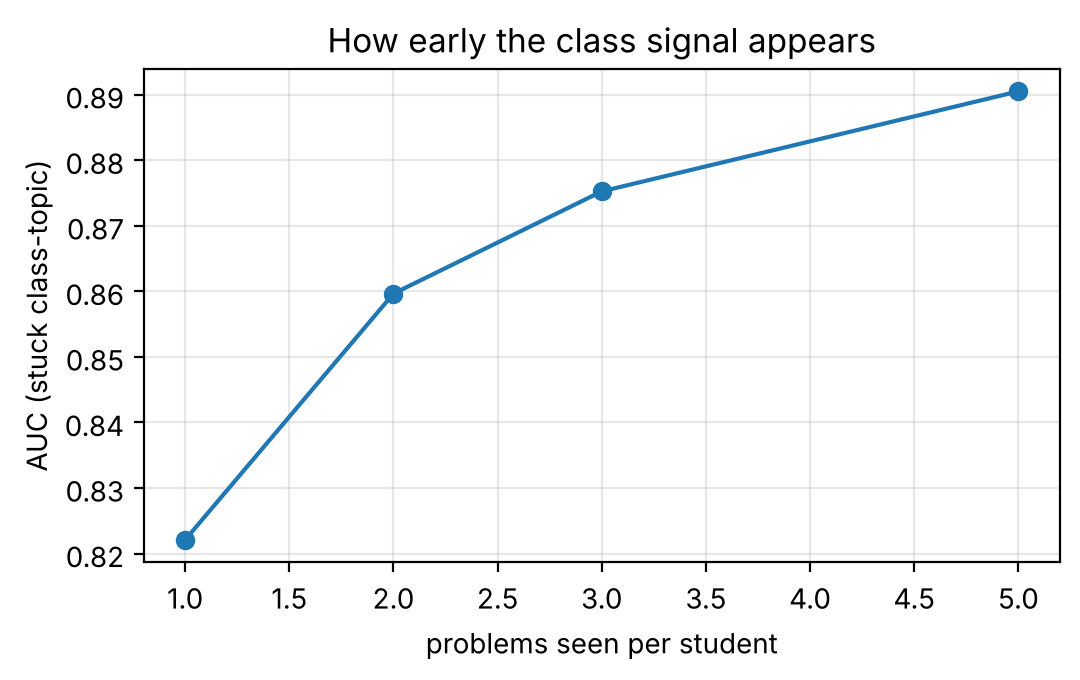

In [5]:
ks = [1,2,3,5]; aucs = [score(class_table(k), ['topic_difficulty','pct_correct'])[0] for k in ks]
for k, a in zip(ks, aucs): print(f"first {k} problem(s) per student: AUC {a:.3f}")
plt.figure(figsize=(5.5,3.5)); plt.plot(ks, aucs, marker='o')
plt.xlabel('problems seen per student'); plt.ylabel('AUC (stuck class-topic)'); plt.title('How early the class signal appears')
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

Even **one problem per student** gives a useful class-level signal, and it is strong by 3.

## What this suggests for an AI-tutor product
- Summarize per **class and topic**, not just per topic: the same topic is fine in one class and stuck in the next.
- A class view can rank topics by early struggle after a handful of problems, so teachers know where to step in before reading any transcripts.
- Tutor conversations add signal practice data lacks (confusions, misconceptions), which could sharpen this further.

## Caveats
- Middle-school math practice from 2009-2010; "mastery = 3 in a row" is ASSISTments' rule, not a universal one.
- Students who stop early may look unmastered for reasons other than difficulty.

By Jahangir Mammadli · mammadli.dev · Data: ASSISTments 2009-2010 skill builder dataset (Feng, Heffernan & Koedinger, 2009)